# 1. Data understanding
We look at the data before we train any model.

We check:
* how many objects of each class we have
* how big the objects are
* how many objects are on one frame
* how the video clips are different

## Install
Run this cell one time. It installs the libraries we need.

In [1]:
%pip install ultralytics pycocotools

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.




[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Imports and paths
Libraries and the folders for the data, the training files and the figures.

In [2]:
import os
import io
import json
import time
import random
import contextlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageDraw
import torch

In [ ]:
if os.path.exists("/kaggle/input"):
    import glob
    DATA = os.path.dirname(glob.glob("/kaggle/input/**/test_images.csv", recursive=True)[0])
    WORK = "/kaggle/working/work"
elif os.name == "nt":
    DATA = "D:/hw2/data"
    WORK = "D:/hw2/work"
else:
    DATA = "/content/data"
    WORK = "/content/work"

# Figures for the report go to the images folder of the repository.
IMAGES = "../images"
RESULTS_FILE = "experiments.csv"
os.makedirs(WORK, exist_ok=True)
os.makedirs(IMAGES, exist_ok=True)

CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 36
print("data:", DATA)
print("device:", DEVICE)

data: D:/hw2/data
device: cuda


## Download the data
If the data is not on this computer yet, we download it with the Kaggle API (`import kaggle`) and unzip it. You need your Kaggle token. If the data is already there, this cell does nothing.

In [4]:
COMPETITION = "multiple-object-video-detection-hw-2-ucu-ai-2026"

if not os.path.exists(f"{DATA}/test_images.csv"):
    import zipfile
    from getpass import getpass
    os.environ["KAGGLE_API_TOKEN"] = getpass("Kaggle token: ")
    import kaggle
    os.makedirs(DATA, exist_ok=True)
    kaggle.api.competition_download_files(COMPETITION, path=DATA, quiet=False)
    zipfile.ZipFile(f"{DATA}/{COMPETITION}.zip").extractall(DATA)
    os.remove(f"{DATA}/{COMPETITION}.zip")
print(os.listdir(DATA))

['test', 'test_images.csv', 'train', 'val']


## Functions
This notebook uses the functions below. Every function does one simple job.

`find_image` finds the full path of an image file.

In [5]:
def find_image(split, file_name):
    """Find the full path of an image file."""
    options = [f"{DATA}/{file_name}", f"{DATA}/{split}/{file_name}", f"{DATA}/{split}/images/{file_name}"]
    for path in options:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(file_name)

`load_split` reads the COCO annotation file of `train` or `val`. It returns two tables: `images` (one row per frame) and `boxes` (one row per box). Box classes become 0-7 (COCO uses 1-8).

In [6]:
def load_split(split):
    """Read annotations of 'train' or 'val'. Returns two tables: images and boxes."""
    with open(f"{DATA}/{split}/annotations_coco.json") as f:
        coco = json.load(f)

    images = pd.DataFrame(coco["images"])
    images = images.rename(columns={"id": "image_id"})
    if "video" not in images.columns:
        images["video"] = images["file_name"].str.split("/").str[-2]
    if "frame_id" not in images.columns:
        images["frame_id"] = images.groupby("video").cumcount()
    images["path"] = [find_image(split, name) for name in images["file_name"]]

    boxes = pd.DataFrame(coco["annotations"])
    if "iscrowd" not in boxes.columns:
        boxes["iscrowd"] = 0
    boxes["x"] = [b[0] for b in boxes["bbox"]]
    boxes["y"] = [b[1] for b in boxes["bbox"]]
    boxes["w"] = [b[2] for b in boxes["bbox"]]
    boxes["h"] = [b[3] for b in boxes["bbox"]]
    # COCO class ids are 1..8. We use 0..7.
    boxes["cls"] = boxes["category_id"] - 1
    # Remove empty boxes.
    boxes = boxes[(boxes["w"] > 0) & (boxes["h"] > 0)]

    images = images[["image_id", "width", "height", "video", "frame_id", "path"]]
    boxes = boxes[["image_id", "cls", "iscrowd", "x", "y", "w", "h"]]
    return images, boxes

`show_boxes` draws true boxes (green), predictions (red) and ignored regions (gray) on a frame.

In [7]:
def show_boxes(ax, path, gt_boxes=None, prediction=None, min_score=0.3, title=""):
    """Draw ground truth (green), predictions (red) and ignored regions (gray)."""
    ax.imshow(Image.open(path))
    if gt_boxes is not None:
        for b in gt_boxes.itertuples():
            if b.iscrowd == 1:
                ax.add_patch(patches.Rectangle((b.x, b.y), b.w, b.h, color="gray", alpha=0.4))
            else:
                ax.add_patch(patches.Rectangle((b.x, b.y), b.w, b.h, fill=False, edgecolor="lime"))
    if prediction is not None:
        boxes, scores, classes = prediction
        for box, score in zip(boxes, scores):
            if score >= min_score:
                x1, y1, x2, y2 = box
                ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red"))
    ax.set_title(title)
    ax.axis("off")

## 1.1 Load the annotations
We read the COCO files of train and val. We get two tables:
* `images`: one row per frame
* `boxes`: one row per box

Boxes with `iscrowd = 1` are **ignored regions**. These are crowds or parking lots with no labels. A detection there is not an error.

In [8]:
train_images, train_boxes = load_split("train")
val_images, val_boxes = load_split("val")
test = pd.read_csv(f"{DATA}/test_images.csv")

train_images["split"] = "train"
val_images["split"] = "val"
train_boxes["split"] = "train"
val_boxes["split"] = "val"

images = pd.concat([train_images, val_images], ignore_index=True)
boxes = pd.concat([train_boxes, val_boxes], ignore_index=True)

objects = boxes[boxes["iscrowd"] == 0].copy()
ignored = boxes[boxes["iscrowd"] == 1]

# One number for the size of a box: the square root of its area, in pixels.
objects["size"] = np.sqrt(objects["w"] * objects["h"])

## 1.2 Overview
We count clips, frames, objects and ignored regions in each split.

In [9]:
overview = pd.DataFrame({
    "clips": images.groupby("split")["video"].nunique(),
    "frames": images.groupby("split").size(),
    "objects": objects.groupby("split").size(),
    "ignored regions": ignored.groupby("split").size(),
})
overview.loc["test"] = [test["clip"].nunique(), len(test), None, None]
overview

,clips,frames,objects,ignored regions
split,,,,
train,56.0,24201.0,1105516.0,510744.0
val,7.0,2846.0,114132.0,31960.0
test,48.0,3811.0,NaN,NaN


## 1.3 Checks
Frames of one clip look almost the same. So train and val must have **different clips**. If not, the validation score is too high.

We also check that all boxes are inside the image and we look at the image sizes.

In [10]:
shared_clips = set(train_images["video"]) & set(val_images["video"])
print("clips in train and val at the same time:", len(shared_clips))

with_size = objects.merge(images[["split", "image_id", "width", "height"]], on=["split", "image_id"])
outside = (with_size["x"] + with_size["w"] > with_size["width"] + 1) | (with_size["y"] + with_size["h"] > with_size["height"] + 1)
print("boxes outside the image:", int(outside.sum()))

print("image sizes in train and val:", sorted(set(zip(images["width"], images["height"]))))
print("image sizes in test:", sorted(set(zip(test["width"], test["height"]))))

clips in train and val at the same time: 0
boxes outside the image: 0
image sizes in train and val: [(1344, 756), (1360, 765), (1904, 1071), (1920, 1080), (2688, 1512), (2720, 1530), (3840, 2160)]
image sizes in test: [(680, 382), (960, 540), (1344, 756), (1360, 764), (1904, 1072), (1920, 1080)]


## 1.4 Classes
How many objects of each class we have.

In [11]:
class_counts = objects.groupby(["cls", "split"]).size().unstack()
class_counts.index = [CLASSES[i] for i in class_counts.index]
class_counts["share, %"] = (class_counts.sum(axis=1) / class_counts.values.sum() * 100).round(1)
class_counts.sort_values("share, %", ascending=False)

split,train,val,"share, %"
car,505301,31821,44.0
person,328701,50312,31.1
motor,102819,12025,9.4
van,46940,6842,4.4
bicycle,40255,6022,3.8
tricycle,41349,5487,3.8
truck,30498,1359,2.6
bus,9653,264,0.8


## 1.5 Object sizes
COCO uses three groups:
* small: smaller than 32 px
* medium: from 32 to 96 px
* large: bigger than 96 px

In [12]:
print(objects["size"].describe(percentiles=[0.1, 0.5, 0.9]).round(1))
print()
print("small:", round((objects["size"] < 32).mean() * 100, 1), "%")
print("medium:", round(((objects["size"] >= 32) & (objects["size"] < 96)).mean() * 100, 1), "%")
print("large:", round((objects["size"] >= 96).mean() * 100, 1), "%")

count    1219648.0
mean          57.1
std           38.9
min            7.7
10%           24.2
50%           46.4
90%          101.4
max          703.0
Name: size, dtype: float64

small: 24.4 %
medium: 64.1 %
large: 11.6 %


## 1.6 Objects per frame and per clip
First we count objects on every frame. Then we make a table with one row per clip.

In [13]:
counts = objects.groupby(["split", "image_id"]).size().rename("objects").reset_index()
per_frame = images.merge(counts, on=["split", "image_id"], how="left")
per_frame["objects"] = per_frame["objects"].fillna(0)
print(per_frame.groupby("split")["objects"].describe().round(1))

per_clip = per_frame.groupby(["split", "video"]).agg(
    frames=("image_id", "size"),
    width=("width", "first"),
    objects_per_frame=("objects", "mean"),
)
per_clip.round(1).sort_values("objects_per_frame")

         count  mean   std  min   25%   50%   75%    max
split                                                   
train  24201.0  45.7  31.6  0.0  22.0  43.0  57.0  180.0
val     2846.0  40.1  26.8  8.0  16.0  37.0  51.8  116.0


frames  width  objects_per_frame
split video                                               
train uav0000218_00001_v     225   2688                5.1
      uav0000266_04830_v     116   2688                6.1
      uav0000266_03598_v     548   2688                6.5
      uav0000263_03289_v     725   1904                6.5
      uav0000099_02109_v    1255   1344                7.1
...                          ...    ...                ...
      uav0000150_02310_v     348   2688              108.9
      uav0000072_04488_v      85   1904              110.4
      uav0000124_00944_v     398   2688              124.6
      uav0000126_00001_v     412   2688              132.2
      uav0000138_00000_v     213   2688              143.0

[63 rows x 3 columns]

## 1.7 Plots
Three plots: objects per class, box sizes and objects per frame. We save them for the report.

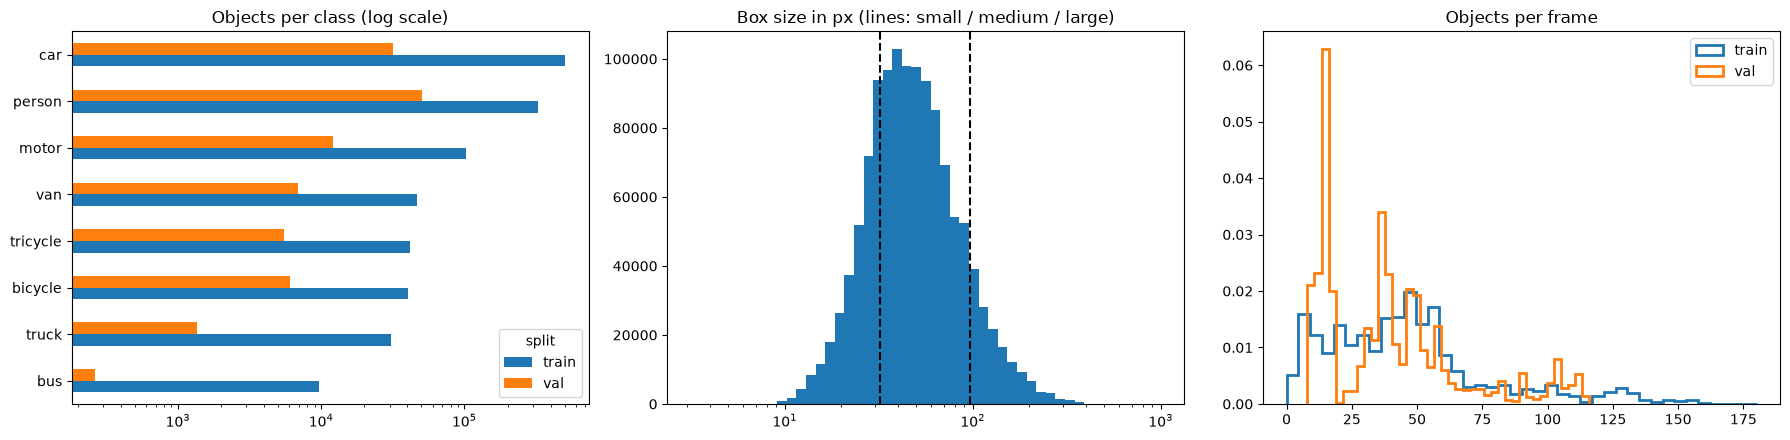

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

class_counts.drop(columns="share, %").sort_values("train").plot.barh(ax=ax[0], logx=True)
ax[0].set_title("Objects per class (log scale)")

ax[1].hist(objects["size"], bins=np.logspace(0.5, 3, 50))
ax[1].axvline(32, color="black", linestyle="--")
ax[1].axvline(96, color="black", linestyle="--")
ax[1].set_xscale("log")
ax[1].set_title("Box size in px (lines: small / medium / large)")

for split in ["train", "val"]:
    values = per_frame[per_frame["split"] == split]["objects"]
    ax[2].hist(values, bins=40, density=True, histtype="step", linewidth=2, label=split)
ax[2].legend()
ax[2].set_title("Objects per frame")

plt.tight_layout()
plt.savefig(f"{IMAGES}/01_eda_plots.png", dpi=110)
plt.show()

## 1.8 Boxes on frames
We draw the boxes on one frame with few objects and one frame with many objects. Green = object. Gray = ignored region.

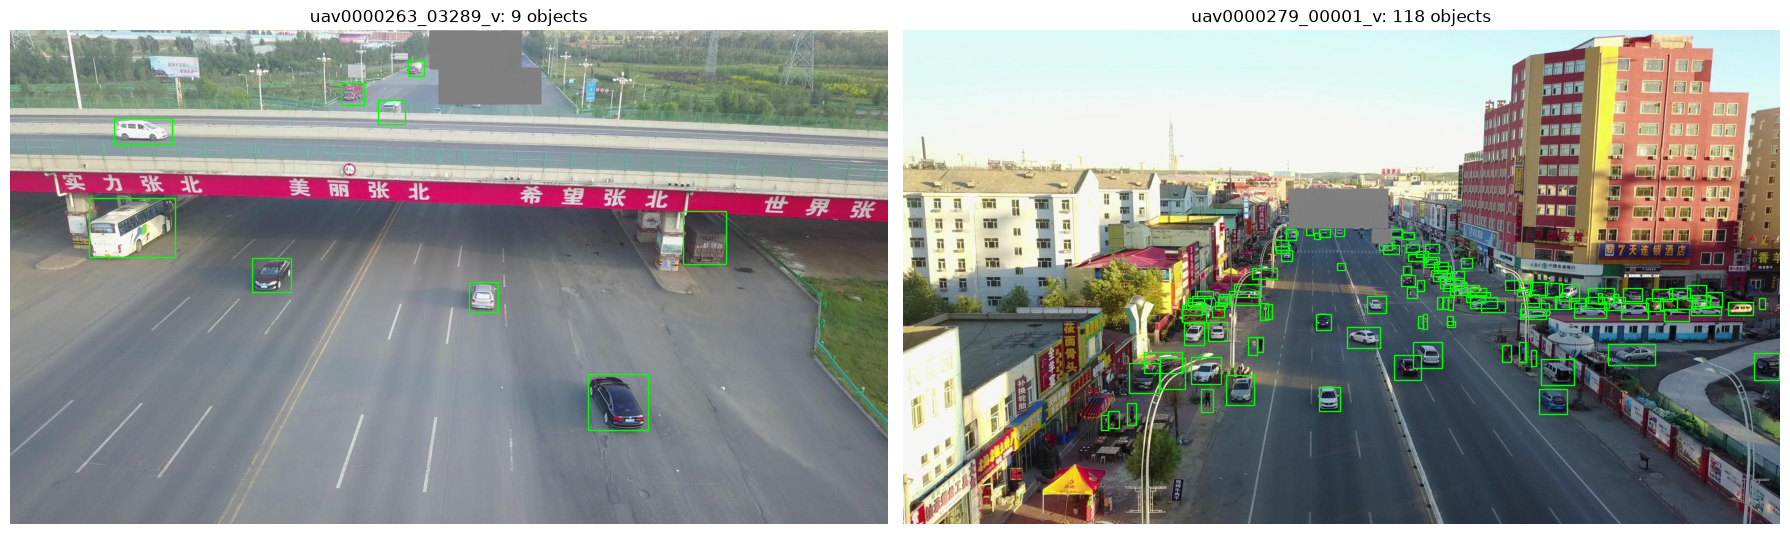

In [15]:
train_frames = per_frame[per_frame["split"] == "train"].sort_values("objects").reset_index(drop=True)
few = train_frames.iloc[len(train_frames) // 10]
many = train_frames.iloc[len(train_frames) * 95 // 100]

fig, ax = plt.subplots(1, 2, figsize=(18, 6))
for a, frame in zip(ax, [few, many]):
    frame_boxes = train_boxes[train_boxes["image_id"] == frame["image_id"]]
    show_boxes(a, frame["path"], frame_boxes, title=f"{frame['video']}: {int(frame['objects'])} objects")
plt.tight_layout()
plt.savefig(f"{IMAGES}/01_eda_frames.png", dpi=110)
plt.show()

## Conclusions
* The most common class: **car** (44.0 %, 537 122 objects). The rarest class: **bus** (0.8 %, 9 917 objects).
* Share of small objects: **24.4 %** (medium 64.1 %, large 11.6 %). Median box size: **46.4 px** (10 % of boxes are smaller than 24.2 px).
* Median objects per frame: **43** in train and **37** in val (max 180 and 116).
* Objects per frame in one clip: from **5.1** to **143.0** on average.
* Ignored regions: 510 744 in train and 31 960 in val.
* No clip is in train and val at the same time. No box is outside the image.
* Train and val images are up to 3840 x 2160 px. Test images are smaller: up to 1920 x 1080 px.

**What this means for our models**
* **Input size.** The frames are very big and the objects are small. If we make a 2688 px frame 640 px wide, a box of 46 px becomes about 11 px. Small objects almost disappear. So a bigger input size (1024 px) or tiles (crops of the frame) should help. We do not need a size bigger than 1024 px, because the test frames are only up to 1920 px.
* **Anchors.** Most boxes are between 24 and 100 px. The default anchors start at 32 px, so they are too big for many objects. We try smaller anchors (from 16 px) in notebooks 03 and 04.
* **Dense scenes.** One frame can have up to 180 objects. The model must give many boxes per frame (we keep up to 500). NMS must not remove real objects that stand close to each other.
* **Class balance.** There are about 50 times more cars than buses. The model will learn rare classes (bus, truck) worse. In val there are only 264 buses, so the score for this class can change a lot between runs.
* **Ignored regions.** There are many of them. We paint them gray in the training images. Without this the model learns that crowds and parking lots are background.
* **Clips are very different.** Some clips have 5 objects per frame, others have more than 140. So we split by clip, not by frame. We take every N-th frame, because frames next to each other are almost the same.
* **Augmentation.** The camera looks from above, so a left-right flip makes a new and correct example. Colour changes help with different light in different clips.